# Training Change Models and Generating Confusion Matrices for BENCH

This project utilizes one shell (b = 0, 1200) from the Brain Tumor Connectomics dataset (OpenNeuro Accession Number: ds001226; no DOI).

--------

## Loading Files and Packages

In [1]:
import numpy as np, matplotlib.pyplot as plt, numba, os, random, scipy, subprocess
import scipy.stats as st, sys, seaborn as sns, pandas as pd, matplotlib.pyplot as plt, sys
from sklearn.metrics import confusion_matrix
from joblib import Parallel, delayed

from bench import diffusion_models, model_inversion, change_model, acquisition, plot
from bench.diffusion_models import sample_signal, standard_model


In [2]:
bvecs = "/Users/ecd25/Desktop/BENCH/one_versus_many_og/protocols/pre_1200_bvecs"
bvals = "/Users/ecd25/Desktop/BENCH/one_versus_many_og/protocols/pre_1200_bvals"
standard_model_dt = "/Users/ecd25/Desktop/BENCH/one_versus_many_og/trained_models/ss_preop_standard_model_dt"

--------

## Training the Single-Shell Change Model

In [3]:
!bench diff-train --model standard_model --bvals $bvals --summarytype dt --output $standard_model_dt

Parameters of standard_model are:['s_iso', 's_in', 's_ex', 'odi', 'd_iso', 'd_in', 'd_ex', 'tau']
The model is trained on the following summary measurements: ['b0.0_mean', 'b1.2_md', 'b1.2_fa']
Generating 10000 training samples...
Training models of change for ['s_iso', 's_in', 's_ex', 'odi', 'd_iso', 'd_in', 'd_ex', 'tau']. /rThis may take up to a few hours depending on the number of samples and the number of change vectors.
Processing Jobs: 100%|██████████████████████████| 8/8 [00:00<00:00, 5182.15it/s]
optimized regression weights for s_iso meanoptimized regression weights for d_ex mean

optimized regression weights for s_in mean
optimized regression weights for d_in mean
optimized regression weights for odi mean
optimized regression weights for d_iso mean
optimized regression weights for tau mean
optimized regression weights for s_ex mean
optimized regression weights for odi covariance
optimized regression weights for s_in covariance
optimized regression weights for s_ex covariance

In [4]:
forward_model = diffusion_models.standard_model
shm_deg = 2

acq = acquisition.Acquisition.from_bval_bvec(bvals, bvecs, b0_threshold=0.5)
func_bench, measurement_names = change_model.summary_decorator(
    forward_model, bvals=acq.bvals, bvecs=acq.bvecs, summary_type='sh', sh_degree=2)
priors_bench = diffusion_models.prior_distributions[forward_model.__name__]

In [5]:
tr = change_model.Trainer(
    forward_model=func_bench, 
    kwargs={'noise_std':0},
    priors=priors_bench, 
    measurement_names=measurement_names)

mdl = tr.train(n_samples=200, verbose=1)

Generating 200 training samples...
Training models of change for ['s_iso', 's_in', 's_ex', 'odi', 'd_iso', 'd_in', 'd_ex', 'tau']. /rThis may take up to a few hours depending on the number of samples and the number of change vectors.
Processing Jobs: 100%|██████████| 8/8 [00:00<00:00, 10796.15it/s]
 mu optimization for d_ex: Optimization terminated successfully.
 function value:1.9796310626325493, 24
 mu optimization for tau: Optimization terminated successfully.
 function value:128.78394355023647, 27
 mu optimization for d_iso: Optimization terminated successfully.
 function value:0.0023011386176101777, 24
 mu optimization for s_ex: Desired error not necessarily achieved due to precision loss.
 function value:162.68151988692253, 28
 mu optimization for d_in: Optimization terminated successfully.
 function value:5.883804781972971, 26
 mu optimization for s_iso: Optimization terminated successfully.
 function value:0.0019938093969894726, 25
 mu optimization for s_in: Optimization termin

---------

## Evaluating BENCH Against Ground Truth Simmulations

In [6]:
n_test_samples = 100
noise_level = 0.02
effect_size = 0.3

true_change, data, data2, sn = tr.generate_test_samples(
        n_samples=n_test_samples, noise_std=noise_level, n_repeats=50, effect_size=effect_size, parallel=True)
    
probs, infered_change_bench, amount, _ = mdl.infer(data, data2 - data, sn)

Generating 100 test samples:
Processing Jobs: 100%|██████████| 100/100 [00:03<00:00, 29.01it/s]
running inference for 100 samples ...
Processing Jobs: 100%|██████████| 100/100 [00:02<00:00, 43.59it/s]
number of samples with nan posterior: 0


<Axes: title={'center': 'BENCH: BTC Glioma Protocol'}, xlabel='Actual change', ylabel='Inferred Change'>

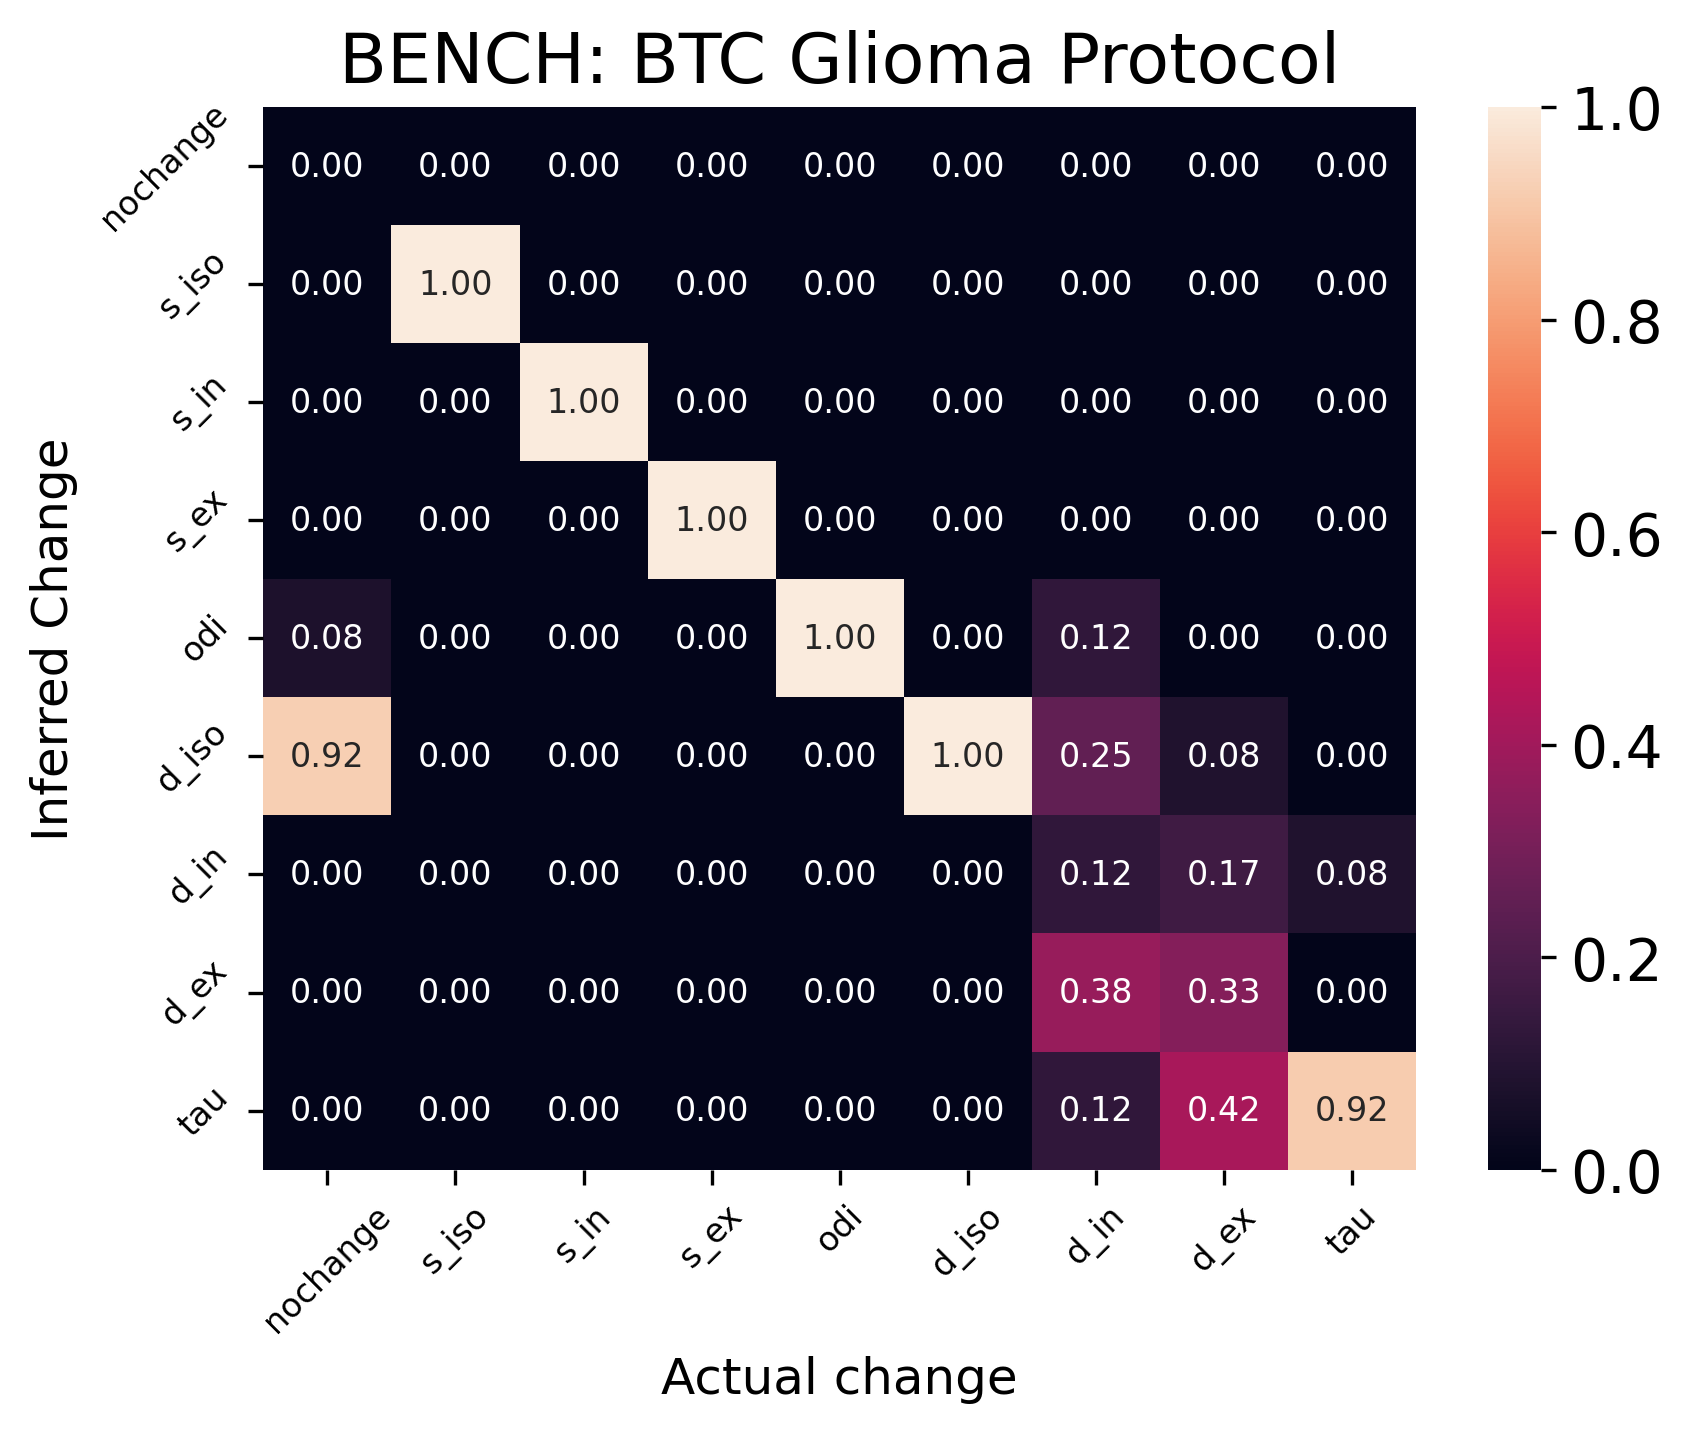

In [7]:
conf_mat = confusion_matrix(true_change, infered_change_bench, normalize='true')
plot.plot_conf_mat(conf_mat, param_names=mdl.model_names, title='BENCH: BTC Glioma Protocol')

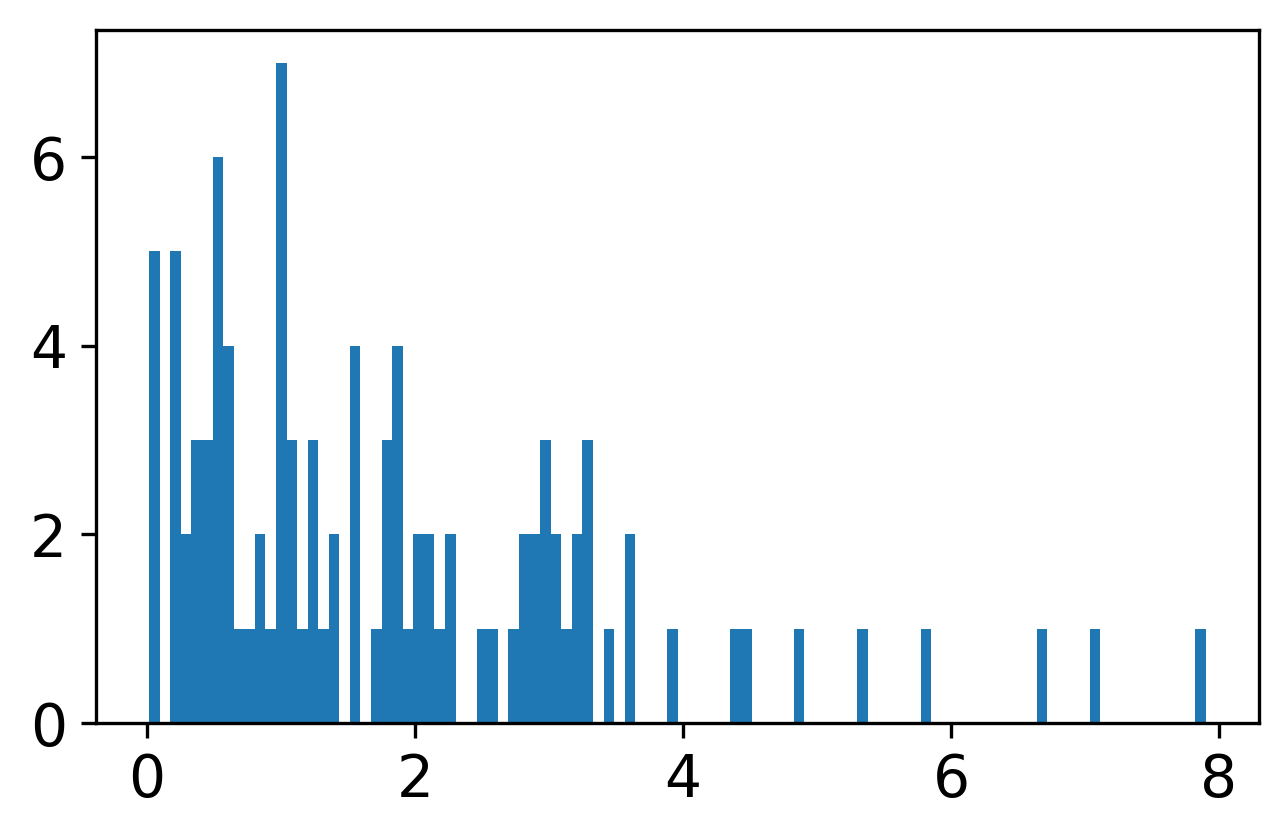

In [8]:
dv, offset, deviation = mdl.estimate_quality_of_fit(data, data2 - data, sn, infered_change_bench, amount)
plt.hist(deviation, 100);

-------

## Comparing BENCH with Model Inversion of Same Protocol

In [9]:
def model_inv_tr(acq, noise_level, **p):
    return forward_model(bval=acq.bvals, bvec=acq.bvecs,**p) + noise_level * np.random.randn(acq.bvecs.shape[0])

def model_inv(**p):
    return forward_model(bval=acq.bvals, bvec=acq.bvecs,**p)

priors_inv = dict()
priors_inv['s_iso'] = st.truncnorm(loc=.5, scale=.2, a=-.5 / .2, b=np.inf)
priors_inv['s_in'] = st.truncnorm(loc=.5, scale=.2, a=-.5 / .2, b=np.inf)
priors_inv['s_ex'] = st.truncnorm(loc=.5, scale=.2, a=-.5 / .2, b=np.inf)
priors_inv.update(priors_bench)
del priors_inv[('s_iso', 's_in', 's_ex')]


tr_inv = change_model.Trainer(forward_model=model_inv_tr, kwargs={'noise_level':0, 'acq':acq}, priors=priors_inv)

true_change_inv, sig1, sig2, sn = tr_inv.generate_test_samples(parallel=False, 
    n_samples=n_test_samples, noise_std=noise_level, n_repeats=2, effect_size=effect_size)
    
def tmp_func(j):
    pe1, std1 = model_inversion.map_fit(sig1[j], np.eye(len(sig1[j])), model_inv, priors_inv)
    pe2, std2 = model_inversion.map_fit(sig2[j], np.eye(len(sig2[j])), model_inv, priors_inv)
        
    return model_inversion.infer_change(np.atleast_2d(pe1), np.atleast_2d(std1), 
                                        np.atleast_2d(pe2), np.atleast_2d(std2), alpha=0.05)

res = Parallel(n_jobs=-1, verbose=True)(delayed(tmp_func)(j) for j in range(n_test_samples))
infered_change_inv = np.squeeze(np.array(res)[:, 0])

Generating 100 test samples:


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
/Users/ecd25/miniconda3/envs/numba-py311/lib/python3.11/site-packages/bench/model_inversion.py:63: RuntimeWarning: invalid value encountered in sqrt
  std = 1 / np.sqrt(np.diag(h))
[Parallel(n_jobs=-1)]: Done  26 tasks      | elapsed:    3.8s
/Users/ecd25/miniconda3/envs/numba-py311/lib/python3.11/site-packages/bench/model_inversion.py:63: RuntimeWarning: invalid value encountered in sqrt
  std = 1 / np.sqrt(np.diag(h))
/Users/ecd25/miniconda3/envs/numba-py311/lib/python3.11/site-packages/bench/model_inversion.py:63: RuntimeWarning: invalid value encountered in sqrt
  std = 1 / np.sqrt(np.diag(h))
/Users/ecd25/miniconda3/envs/numba-py311/lib/python3.11/site-packages/bench/model_inversion.py:63: RuntimeWarning: invalid value encountered in sqrt
  std = 1 / np.sqrt(np.diag(h))
/Users/ecd25/miniconda3/envs/numba-py311/lib/python3.11/site-packages/bench/model_inversion.py:63: RuntimeWarning: invalid value encounte

<Axes: title={'center': 'Parameter estimation: BTC Glioma Protocol'}, xlabel='Actual change', ylabel='Inferred Change'>

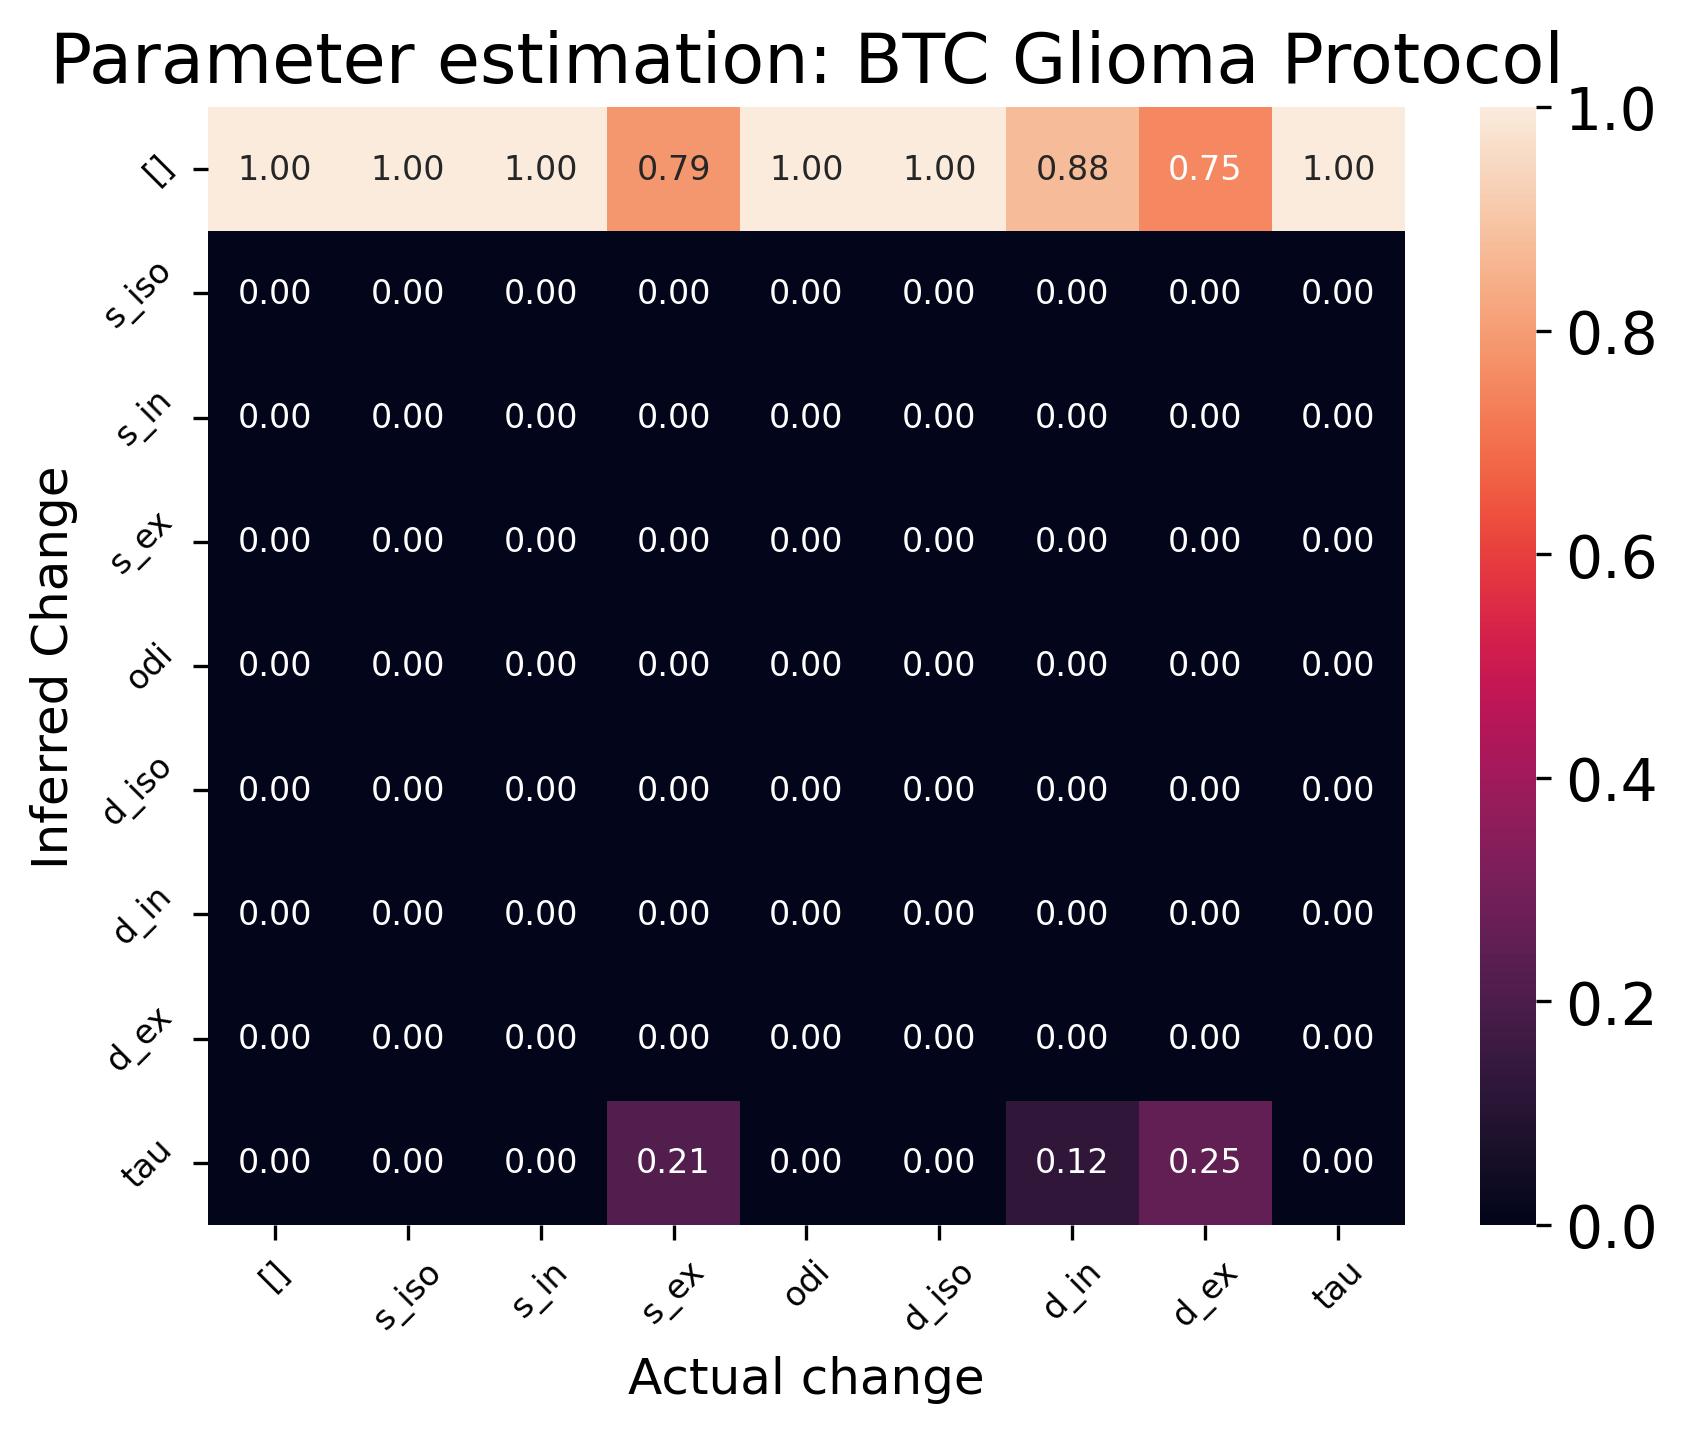

In [10]:
conf_mat_inv = confusion_matrix(true_change_inv, infered_change_inv, normalize='true')
plot.plot_conf_mat(conf_mat_inv, ['[]'] + list(priors_inv.keys()), title='Parameter estimation: BTC Glioma Protocol')